# Preparação dos dados e baseline

## Importando as bibliotecas e dados

In [1]:
import sys
import os
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from src.knn_utils import proporcoes, metricas

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

df = pd.read_csv("../data/raw/dupla_08.csv")

## Divisão em treino e teste

Separamos os atributos previsores (`indice_01` a `indice_09`) da variável alvo e dividimos em 75% para treino e 25% para teste, com `random_state=42`. Para decidir sobre a estratificação, comparamos as duas alternativas.

In [2]:
X = df.drop(columns="classe")
y = df["classe"]

split_simples = train_test_split(X, y, test_size=0.25, random_state=42)
split_estrat = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

comparacao = pd.concat({
    "original": y.value_counts(normalize=True).to_frame("total"),
    "sem estratificação": proporcoes(split_simples[2], split_simples[3]),
    "com estratificação": proporcoes(split_estrat[2], split_estrat[3]),
}, axis=1)
comparacao * 100

original sem estratificação         com estratificação        
               total             treino   teste             treino   teste
classe                                                                    
nivel_baixo  50.9677            50.1075 53.5484            50.9677 50.9677
nivel_alto   49.0323            49.8925 46.4516            49.0323 49.0323

In [3]:
X_train, X_test, y_train, y_test = split_estrat
print("treino:", X_train.shape, "| teste:", X_test.shape)
print(y_train.value_counts().to_dict(), y_test.value_counts().to_dict())

treino: (465, 9) | teste: (155, 9)
{'nivel_baixo': 237, 'nivel_alto': 228} {'nivel_baixo': 79, 'nivel_alto': 76}


* Com o resultado conseguimos entender que a distribuição das classes deve ser considerada na divisão. 

* Sem estratificação, o teste ficou com 53,5%/46,5%, diferente dos 51%/49% do total. Com `stratify=y`, treino e teste mantêm essa proporção, deixando a comparação mais justa.


### Salvando os conjuntos preparados em `data/processed/`


In [4]:
os.makedirs("../data/processed", exist_ok=True)

train_df = X_train.copy()
train_df["classe"] = y_train
test_df = X_test.copy()
test_df["classe"] = y_test

train_df.to_csv("../data/processed/train.csv", index_label="id")
test_df.to_csv("../data/processed/test.csv", index_label="id")

print("data/processed/train.csv:", train_df.shape)
print("data/processed/test.csv: ", test_df.shape)

data/processed/train.csv: (465, 10)
data/processed/test.csv:  (155, 10)


## Baseline

O baseline é um K-NN com k = 5 nos dados originais, sem escalonamento.

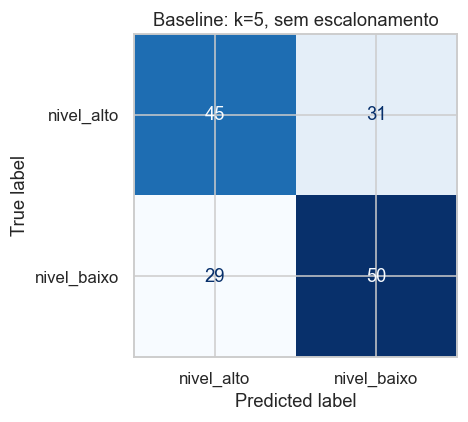

,baseline (teste)
accuracy,0.6129
precision,0.6127
recall,0.6125
f1,0.6125


In [5]:
baseline = KNeighborsClassifier(n_neighbors=5)
baseline.fit(X_train.values, y_train)
pred_base_tr = baseline.predict(X_train.values)
pred_base = baseline.predict(X_test.values)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_base, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Baseline: k=5, sem escalonamento")
plt.tight_layout()
plt.show()


m_tr, m_te = metricas(y_train, pred_base_tr), metricas(y_test, pred_base)
res_baseline = pd.DataFrame([{
    "f1_treino": m_tr["f1"], "f1_teste": m_te["f1"], "gap": m_tr["f1"] - m_te["f1"],
    "acc_teste": m_te["accuracy"], "prec_teste": m_te["precision"], "rec_teste": m_te["recall"],
}], index=["A - dados originais"])
res_baseline.to_csv("../data/processed/baseline.csv", index_label="modelo")

pd.Series(m_te, name="baseline (teste)").to_frame()

In [6]:
print(classification_report(y_test, pred_base, digits=3))

              precision    recall  f1-score   support

  nivel_alto      0.608     0.592     0.600        76
 nivel_baixo      0.617     0.633     0.625        79

    accuracy                          0.613       155
   macro avg      0.613     0.613     0.613       155
weighted avg      0.613     0.613     0.613       155



## Resultados  do baseline

- Baseline: 61,3% de acurácia e F1 macro de 0,613.
- O desempenho foi baixo nas duas classes, principalmente porque indice_03 domina a distância.
- Usamos `average="macro"`. O padrão do `scikit-learn` (`binary`) exigiria escolher uma classe positiva, e aqui as duas têm o mesmo peso. O macro tira a média simples entre as classes e continua valendo se houvesse três.
- Como estão balanceadas (51%/49%), as métricas ficam próximas entre si.
- O micro seria igual à acurácia e não acrescentaria informação.